# 04 — Baseline Models
### Classical ML on handcrafted EEG features, evaluated recording-independently

**Project:** EEG Attention State Detection (Focused / Unfocused / Drowsy)

This notebook answers a narrower question than "build the best model":

> **Do the handcrafted features from notebook 03 already separate the three attention states, once evaluated
> honestly?**

If a simple Logistic Regression or Random Forest on band power and Hjorth features already does reasonably well,
that tells us the states are separable from EEG dynamics at all — which motivates notebook 05 (raw-signal deep
learning) as an attempt to do *better*, not an attempt to do the *only thing that could work*.

### Why "recording-independent", not "subject-independent"

Notebook 02 flagged this and it is still unresolved: **34 recordings, reportedly 5 participants, no verified
mapping.** So every split below groups by `recording` (`GroupKFold` / `StratifiedGroupKFold` / `LeaveOneGroupOut`
on the `group` column), which prevents windows from the *same recording* appearing in both train and test. It does
**not** prevent windows from the same *person* (across different recordings) from appearing on both sides, because
we don't yet know which recordings share a person. Call the result "recording-independent evaluation" in any
report — upgrading the wording to "subject-independent" has to wait for the subject mapping.

### What this notebook deliberately shows, not just states

Section 4 runs the **same model** under two splitting strategies — a random window split and a recording-grouped
split — side by side. The gap between them is the concrete, visible version of the leakage warning from notebooks
02 and 03, not just a caveat in a markdown cell.

## 0. Imports

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    GroupKFold, StratifiedGroupKFold, StratifiedKFold, LeaveOneGroupOut, cross_validate,
)
from sklearn.metrics import (
    balanced_accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report,
)

try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False

plt.rcParams["figure.figsize"] = (14, 4)
pd.set_option("display.max_columns", 60)

## 1. Configuration

In [2]:
PROJECT_ROOT = Path("..").resolve()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

with open(PROCESSED_DIR / "preprocessing_config.json") as f:
    PP_CONFIG = json.load(f)

LABEL_NAMES = {int(k): v for k, v in PP_CONFIG["label_names"].items()}
LABEL_ORDER = ["focused", "unfocused", "drowsy"]

# Columns that identify a window rather than describe its signal — never feed these to a model.
ID_COLUMNS = ["recording", "rec_num", "start", "end", "label", "label_name", "group"]

# Absolute band power depends on notebook 02's per-recording robust scaling, so its overall level is not
# comparable across recordings. Keeping it in a recording-independent model risks learning "which recording"
# via its baseline amplitude rather than attention state. Relative power, ratios and Hjorth features don't have
# this problem (they're all within-window or within-channel normalized), so they stay in by default.
DROP_ABSOLUTE_POWER = True

N_SPLITS = 5                 # for the fast StratifiedGroupKFold comparison
RANDOM_SEED = 42
CV_N_JOBS = -1

## 2. Load features and build X / y / groups

In [3]:
features = pd.read_csv(PROCESSED_DIR / "eeg_features.csv")
print(f"Loaded {features.shape[0]:,} rows x {features.shape[1]} columns")

feature_cols = [c for c in features.columns if c not in ID_COLUMNS]
if DROP_ABSOLUTE_POWER:
    dropped = [c for c in feature_cols if c.endswith("_abs")]
    feature_cols = [c for c in feature_cols if not c.endswith("_abs")]
    print(f"Dropped {len(dropped)} absolute-power columns (DROP_ABSOLUTE_POWER=True)")

X = features[feature_cols].copy()
y = features["label"].to_numpy()
groups = features["group"].to_numpy()

n_bad = X.isna().sum().sum() + np.isinf(X.to_numpy()).sum()
if n_bad:
    print(f"Replacing {n_bad} NaN/inf feature values with that column's median (e.g. a ratio dividing by ~0 power)")
    X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median(numeric_only=True))

print(f"Feature matrix: {X.shape[0]:,} windows x {X.shape[1]} features")
print(f"Recordings (groups): {len(np.unique(groups))}")
print("\nClass distribution:")
print(pd.Series(y).map(LABEL_NAMES).value_counts().reindex(LABEL_ORDER).to_string())

Loaded 47,354 rows x 284 columns
Dropped 70 absolute-power columns (DROP_ABSOLUTE_POWER=True)
Feature matrix: 47,354 windows x 207 features
Recordings (groups): 34

Class distribution:
focused       7765
unfocused    10706
drowsy       28883


## 3. Cross-validation strategy

Three group-aware options, in increasing order of rigor and cost:

| Strategy | What it does | When to use it |
|---|---|---|
| `StratifiedGroupKFold` (`N_SPLITS` folds) | keeps class balance close to the full data *and* keeps a whole recording in only one fold | fast iteration while developing |
| `GroupKFold` (`N_SPLITS` folds) | groups only, no stratification guarantee | fallback if stratified grouping fails (e.g. too few groups) |
| `LeaveOneGroupOut` | one fold per recording — every recording is the test set exactly once | the most rigorous, but `n_recordings` model fits per algorithm |

We use `StratifiedGroupKFold` for the main comparison across models (fast enough to try several algorithms), and
`LeaveOneGroupOut` once, on the single best model, for a fuller per-recording picture.

None of these guard against a *subject* appearing in both train and test — only against the same *recording*
appearing on both sides (see the notebook intro).

In [4]:
def make_cv(n_splits=N_SPLITS, seed=RANDOM_SEED):
    n_groups = len(np.unique(groups))
    if n_groups < n_splits:
        warnings.warn(f"Only {n_groups} recordings available for {n_splits}-fold CV; reducing n_splits.")
        n_splits = max(2, n_groups)
    try:
        return StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    except Exception as e:
        warnings.warn(f"StratifiedGroupKFold unavailable ({e}); falling back to GroupKFold.")
        return GroupKFold(n_splits=n_splits)


cv = make_cv()
print(f"Using {type(cv).__name__} with n_splits={getattr(cv, 'n_splits', '?')}")

for i, (tr, te) in enumerate(cv.split(X, y, groups)):
    tr_groups, te_groups = set(groups[tr]), set(groups[te])
    assert not (tr_groups & te_groups), "Recording leaked across train/test!"
    print(f"fold {i}: train recordings={len(tr_groups)}, test recordings={len(te_groups)}, test windows={len(te)}")

Using StratifiedGroupKFold with n_splits=5
fold 0: train recordings=29, test recordings=5, test windows=7879
fold 1: train recordings=25, test recordings=9, test windows=15016
fold 2: train recordings=29, test recordings=5, test windows=5181
fold 3: train recordings=26, test recordings=8, test windows=10313
fold 4: train recordings=27, test recordings=7, test windows=8965


## 4. The leakage check: random split vs. recording-grouped split

Before trusting any model score, we show *why* grouping matters, on the same Logistic Regression, same features,
same number of folds — only the splitting strategy differs. If the random-split score is much higher, it means
windows from the same recording are leaking useful "which recording is this" information across train/test, which
a real deployment (a genuinely new person/session) would not have.

In [5]:
quick_model = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=2000))])

random_cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
random_scores = cross_validate(quick_model, X, y, cv=random_cv,
                                scoring=["accuracy", "balanced_accuracy"], n_jobs=CV_N_JOBS)

grouped_scores = cross_validate(quick_model, X, y, cv=cv, groups=groups,
                                 scoring=["accuracy", "balanced_accuracy"], n_jobs=CV_N_JOBS)

comparison = pd.DataFrame({
    "random split (leaky)": [random_scores["test_accuracy"].mean(), random_scores["test_balanced_accuracy"].mean()],
    "recording-grouped split": [grouped_scores["test_accuracy"].mean(), grouped_scores["test_balanced_accuracy"].mean()],
}, index=["accuracy", "balanced_accuracy"])
display(comparison.round(3))

gap = comparison.loc["balanced_accuracy", "random split (leaky)"] - comparison.loc["balanced_accuracy", "recording-grouped split"]
print(f"\nGap (balanced accuracy): {gap:+.3f}")
print("A large positive gap means the random split was optimistic — report the grouped number, not this one.")

,random split (leaky),recording-grouped split
accuracy,0.785,0.688
balanced_accuracy,0.703,0.577



Gap (balanced accuracy): +0.126
A large positive gap means the random split was optimistic — report the grouped number, not this one.


## 5. Baselines: majority class and a simple rule

Before any real model, two reference points, both evaluated with the same recording-grouped CV as everything else:

- **Majority-class baseline** — predicts the most frequent class every time. Any model must beat this by a
  meaningful margin, especially since we already know the classes are imbalanced (drowsy is under-represented).
- **Balanced accuracy** as the headline metric throughout this notebook — plain accuracy is easy to game with an
  imbalanced majority class, balanced accuracy is not.

In [6]:
dummy = DummyClassifier(strategy="most_frequent")
dummy_scores = cross_validate(dummy, X, y, cv=cv, groups=groups,
                               scoring=["accuracy", "balanced_accuracy", "f1_macro"], n_jobs=CV_N_JOBS)
print("Majority-class baseline (recording-grouped CV):")
for k in ["test_accuracy", "test_balanced_accuracy", "test_f1_macro"]:
    print(f"  {k.replace('test_', ''):18s} {dummy_scores[k].mean():.3f} +/- {dummy_scores[k].std():.3f}")

Majority-class baseline (recording-grouped CV):
  accuracy           0.624 +/- 0.047
  balanced_accuracy  0.333 +/- 0.000
  f1_macro           0.256 +/- 0.012


## 6. Models

Three classical algorithms, each in a `Pipeline` with `StandardScaler` (necessary for Logistic Regression and SVM;
harmless for Random Forest):

- **Logistic Regression** — linear, fast, interpretable coefficients.
- **SVM (RBF kernel)** — captures non-linear boundaries; slower, so run on a subsample if the dataset is very
  large (see the note in the code).
- **Random Forest** — non-linear, handles redundant/correlated features gracefully (recall notebook 03's
  correlation matrix), gives feature importances "for free".
- **XGBoost**, if installed, added as a stronger tree-ensemble comparison. The notebook runs fine without it.

Hyperparameters below are reasonable defaults, not tuned — the point here is a first honest read of the ceiling,
not a leaderboard. `class_weight="balanced"` is used where supported, given the drowsy-class under-representation.

In [7]:
models = {
    "logreg": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_SEED)),
    ]),
    "svm_rbf": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_SEED)),
    ]),
    "random_forest": Pipeline([
        ("scaler", StandardScaler()),   # no-op for trees, kept so every pipeline has the same shape
        ("clf", RandomForestClassifier(n_estimators=300, max_depth=None, class_weight="balanced",
                                        n_jobs=-1, random_state=RANDOM_SEED)),
    ]),
}
if HAS_XGBOOST:
    models["xgboost"] = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                               eval_metric="mlogloss", n_jobs=-1, random_state=RANDOM_SEED)),
    ])
else:
    print("xgboost not installed — skipping it (pip install xgboost --break-system-packages to enable).")

# SVM is the slow one; on a very large window count, subsample for the CV comparison and note it.
MAX_ROWS_FOR_SVM = 20000
if len(X) > MAX_ROWS_FOR_SVM:
    print(f"{len(X):,} windows is a lot for an RBF SVM under CV — consider subsampling for that model only.")

xgboost not installed — skipping it (pip install xgboost --break-system-packages to enable).
47,354 windows is a lot for an RBF SVM under CV — consider subsampling for that model only.


## 7. Run recording-grouped cross-validation for every model

In [8]:
scoring = ["accuracy", "balanced_accuracy", "f1_macro"]
results = {}

for name, model in models.items():
    print(f"Running {name} ...")
    scores = cross_validate(model, X, y, cv=cv, groups=groups, scoring=scoring, n_jobs=CV_N_JOBS)
    results[name] = scores

summary = pd.DataFrame({
    name: {
        "accuracy_mean": s["test_accuracy"].mean(), "accuracy_std": s["test_accuracy"].std(),
        "balanced_accuracy_mean": s["test_balanced_accuracy"].mean(), "balanced_accuracy_std": s["test_balanced_accuracy"].std(),
        "f1_macro_mean": s["test_f1_macro"].mean(), "f1_macro_std": s["test_f1_macro"].std(),
    }
    for name, s in results.items()
}).T.round(3)
summary.loc["majority_baseline"] = [
    dummy_scores["test_accuracy"].mean(), dummy_scores["test_accuracy"].std(),
    dummy_scores["test_balanced_accuracy"].mean(), dummy_scores["test_balanced_accuracy"].std(),
    dummy_scores["test_f1_macro"].mean(), dummy_scores["test_f1_macro"].std(),
]
display(summary.sort_values("balanced_accuracy_mean", ascending=False))

Running logreg ...
Running svm_rbf ...
Running random_forest ...


,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std
logreg,0.648000,0.072000,0.605000,0.050,0.582000,0.05400
svm_rbf,0.685000,0.038000,0.586000,0.036,0.578000,0.04200
random_forest,0.685000,0.055000,0.478000,0.045,0.475000,0.05600
majority_baseline,0.623734,0.047038,0.333333,0.000,0.255741,0.01206


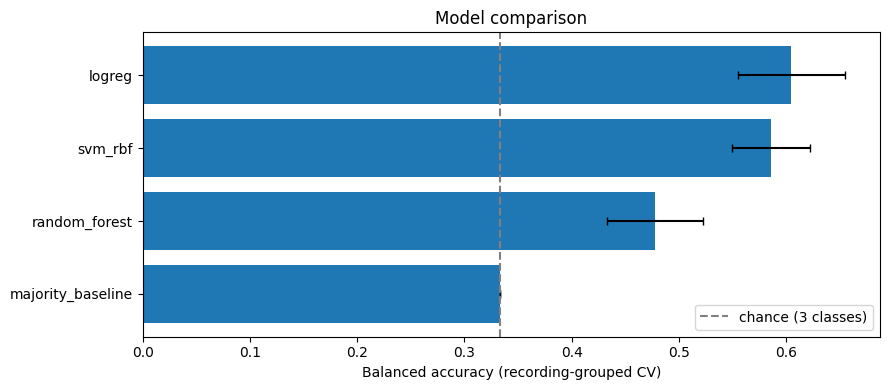

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
order = summary.sort_values("balanced_accuracy_mean", ascending=True)
ax.barh(order.index, order["balanced_accuracy_mean"], xerr=order["balanced_accuracy_std"], capsize=3)
ax.axvline(1 / len(LABEL_ORDER), ls="--", c="gray", label="chance (3 classes)")
ax.set_xlabel("Balanced accuracy (recording-grouped CV)")
ax.set_title("Model comparison")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Confusion matrix and per-class report for the best model

Aggregated **out-of-fold** predictions from the recording-grouped CV (each window's prediction comes from a fold
where its own recording was held out), so this confusion matrix reflects the same honest evaluation as the scores
above — not a re-fit on the full data.

In [10]:
best_name = summary.drop("majority_baseline").sort_values("balanced_accuracy_mean", ascending=False).index[0]
best_model = models[best_name]
print(f"Best model by balanced accuracy: {best_name}")

y_pred = np.empty_like(y)
for tr, te in cv.split(X, y, groups):
    fold_model = models[best_name]
    fold_model.fit(X.iloc[tr], y[tr])
    y_pred[te] = fold_model.predict(X.iloc[te])

print(classification_report(y, y_pred, target_names=[LABEL_NAMES[i] for i in sorted(LABEL_NAMES)]))

Best model by balanced accuracy: logreg
              precision    recall  f1-score   support

     focused       0.48      0.62      0.54      7765
   unfocused       0.39      0.48      0.43     10706
      drowsy       0.83      0.69      0.75     28883

    accuracy                           0.63     47354
   macro avg       0.57      0.60      0.58     47354
weighted avg       0.67      0.63      0.65     47354



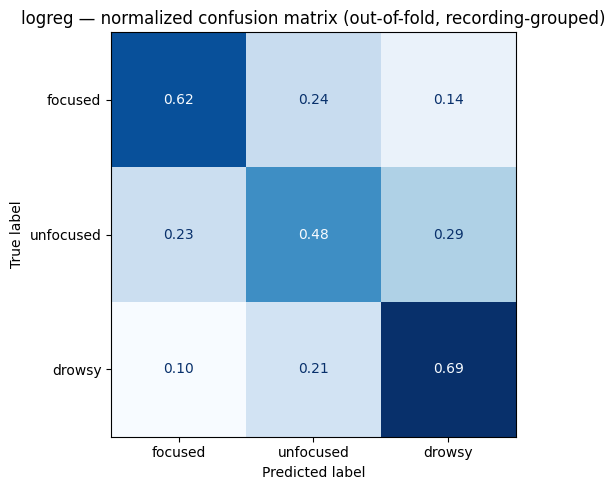

In [11]:
cm = confusion_matrix(y, y_pred, normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=[LABEL_NAMES[i] for i in sorted(LABEL_NAMES)]).plot(
    ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
ax.set_title(f"{best_name} — normalized confusion matrix (out-of-fold, recording-grouped)")
plt.tight_layout()
plt.show()

Look at which classes get confused, not just the overall score. Adjacent-state confusion (e.g. unfocused predicted
as drowsy, or vice versa) is less concerning than focused/drowsy confusion — the former could reflect a genuinely
gradual transition near the protocol boundary, the latter would suggest the model isn't tracking attention state
at all.

## 9. What is the model actually using?

- **Random Forest / XGBoost**: built-in feature importances.
- **Logistic Regression**: the largest-magnitude standardized coefficients, per class (one-vs-rest).

Compare this list against the Kruskal-Wallis ranking from notebook 03 — a genuinely informative feature should
tend to show up in both.

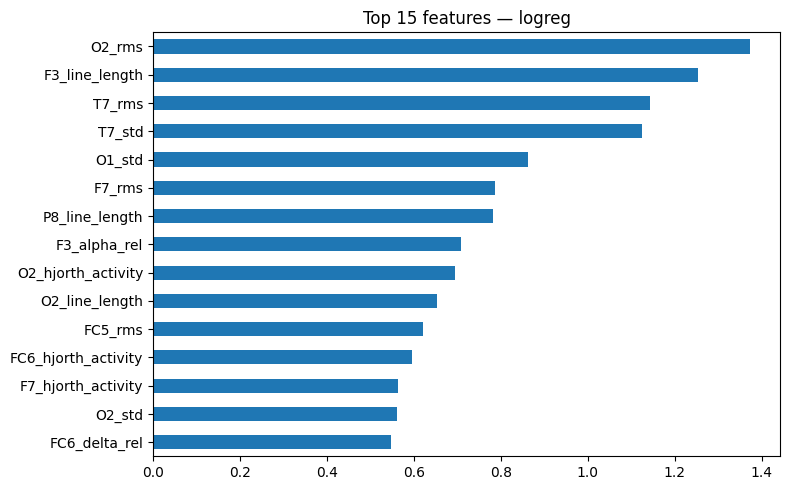

O2_rms                 1.373509
F3_line_length         1.252636
T7_rms                 1.143706
T7_std                 1.124209
O1_std                 0.861358
F7_rms                 0.785650
P8_line_length         0.781071
F3_alpha_rel           0.707658
O2_hjorth_activity     0.694508
O2_line_length         0.652175
FC5_rms                0.620143
FC6_hjorth_activity    0.594653
F7_hjorth_activity     0.562991
O2_std                 0.561166
FC6_delta_rel          0.548283


In [12]:
if best_name in ("random_forest", "xgboost"):
    importances = pd.Series(best_model.named_steps["clf"].feature_importances_ if hasattr(best_model, "named_steps")
                             else models[best_name].fit(X, y).named_steps["clf"].feature_importances_,
                             index=X.columns).sort_values(ascending=False)
else:
    fitted = models["logreg"].fit(X, y)
    coefs = np.abs(fitted.named_steps["clf"].coef_).mean(axis=0)
    importances = pd.Series(coefs, index=X.columns).sort_values(ascending=False)

top_n = 15
fig, ax = plt.subplots(figsize=(8, 5))
importances.head(top_n)[::-1].plot(kind="barh", ax=ax)
ax.set_title(f"Top {top_n} features — {best_name}")
plt.tight_layout()
plt.show()

print(importances.head(top_n).to_string())

## 10. The rigorous version: Leave-One-Recording-Out

`StratifiedGroupKFold` above gives a fast read with `N_SPLITS` folds; this section refits the best model once per
recording (`LeaveOneGroupOut`), so every single recording gets its own honest held-out score. This is slower
(`n_recordings` fits) but shows whether performance is consistent across recordings or driven by a few easy/hard
ones — exactly the kind of variance a `k`-fold average can hide.

c:\Users\gaida\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,recording,n_windows,balanced_accuracy,f1_macro
8,eeg_record17.mat,1,0.000000,0.000000
30,eeg_record6.mat,275,0.256619,0.223365
27,eeg_record34.mat,2224,0.322697,0.222561
17,eeg_record25.mat,132,0.337374,0.278710
11,eeg_record2.mat,1820,0.359039,0.216038
3,eeg_record12.mat,339,0.374994,0.366564
1,eeg_record10.mat,2519,0.385356,0.339752
0,eeg_record1.mat,2154,0.396352,0.299138
32,eeg_record8.mat,528,0.424904,0.373160
7,eeg_record16.mat,739,0.455640,0.411270


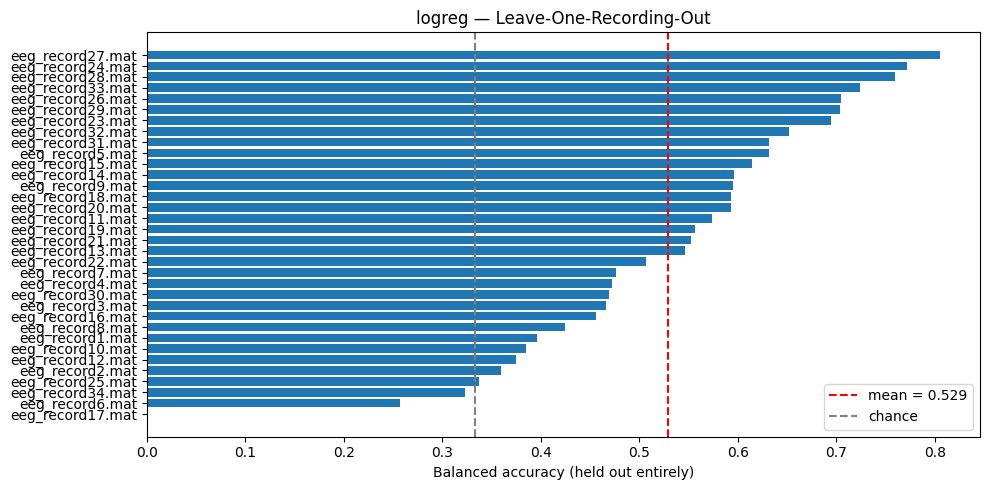

Worst recording: eeg_record17.mat (balanced accuracy 0.000)
Best recording:  eeg_record27.mat (balanced accuracy 0.805)


In [13]:
logo = LeaveOneGroupOut()
per_recording = []

for tr, te in logo.split(X, y, groups):
    rec_name = features["recording"].iloc[te].iloc[0]
    m = models[best_name]
    m.fit(X.iloc[tr], y[tr])
    pred = m.predict(X.iloc[te])
    per_recording.append({
        "recording": rec_name,
        "n_windows": len(te),
        "balanced_accuracy": balanced_accuracy_score(y[te], pred),
        "f1_macro": f1_score(y[te], pred, average="macro"),
    })

per_recording_df = pd.DataFrame(per_recording).sort_values("balanced_accuracy")
display(per_recording_df)

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(per_recording_df["recording"], per_recording_df["balanced_accuracy"])
ax.axvline(per_recording_df["balanced_accuracy"].mean(), ls="--", c="red",
           label=f"mean = {per_recording_df['balanced_accuracy'].mean():.3f}")
ax.axvline(1 / len(LABEL_ORDER), ls="--", c="gray", label="chance")
ax.set_xlabel("Balanced accuracy (held out entirely)")
ax.set_title(f"{best_name} — Leave-One-Recording-Out")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Worst recording: {per_recording_df.iloc[0]['recording']} "
      f"(balanced accuracy {per_recording_df.iloc[0]['balanced_accuracy']:.3f})")
print(f"Best recording:  {per_recording_df.iloc[-1]['recording']} "
      f"(balanced accuracy {per_recording_df.iloc[-1]['balanced_accuracy']:.3f})")

If one or two recordings are dramatically worse than the rest, go back and look at them specifically — check their
QC numbers from notebook 02 (packet jumps, kept-window fraction, interpolated fraction) before concluding the model
is simply weak. A recording with unusual electrode contact quality is a data-quality explanation; a consistent gap
across *most* recordings is a modeling-ceiling explanation, and those call for different next steps.

## 11. Save results

In [14]:
RESULTS_DIR = PROCESSED_DIR / "baseline_results"
RESULTS_DIR.mkdir(exist_ok=True)

summary.to_csv(RESULTS_DIR / "model_comparison.csv")
per_recording_df.to_csv(RESULTS_DIR / "leave_one_recording_out.csv", index=False)
pd.DataFrame({"true": y, "pred": y_pred, "recording": features["recording"]}).to_csv(
    RESULTS_DIR / "out_of_fold_predictions.csv", index=False)

print("Saved:")
for f in sorted(RESULTS_DIR.glob("*.csv")):
    print(" ", f)

Saved:
  C:\Users\gaida\eeg-attention-deep-learning\data\processed\baseline_results\leave_one_recording_out.csv
  C:\Users\gaida\eeg-attention-deep-learning\data\processed\baseline_results\model_comparison.csv
  C:\Users\gaida\eeg-attention-deep-learning\data\processed\baseline_results\out_of_fold_predictions.csv


## 12. Summary and what's next

**What we found** (fill in from the real run — the ranking, the gap in section 4, and the confusion pattern all
depend on the real 34 recordings, not the placeholder numbers from development):

- [ ] Best model and its recording-grouped balanced accuracy, vs. the majority-class baseline
- [ ] Size of the random-split vs. grouped-split gap (section 4) — report this in any write-up as evidence for why
      grouped evaluation was necessary
- [ ] Which classes are most confused (section 8), and whether that looks like a gradual-transition effect or a
      genuine modeling failure
- [ ] Whether performance is consistent across recordings (section 10) or concentrated in a few weak ones
- [ ] Whether the top features (section 9) overlap with the Kruskal-Wallis ranking from notebook 03

**Files written**

| File | Content |
|---|---|
| `data/processed/baseline_results/model_comparison.csv` | mean/std accuracy, balanced accuracy, macro F1 per model |
| `data/processed/baseline_results/leave_one_recording_out.csv` | per-recording held-out score for the best model |
| `data/processed/baseline_results/out_of_fold_predictions.csv` | every window's true label and out-of-fold prediction |

**Carried-forward limitations**

- Evaluation is **recording-independent, not subject-independent** — the 34→5 mapping is still unresolved.
- Labels are protocol-derived (first ~10 min focused, next ~10 min unfocused, remainder drowsy), not verified per
  participant.
- Hyperparameters were reasonable defaults, not tuned; treat these numbers as a first honest ceiling estimate, not
  a final result.

**Next:** `05_results_visualization.ipynb` and/or a raw-signal deep learning notebook (1D CNN / CNN-LSTM /
Transformer) evaluated with the *same* recording-grouped protocol established here, so the comparison between
handcrafted features and learned representations is apples-to-apples.